# Evaluación Cuantitativa del Clasificador de Intención (Data Science Benchmark)

**Proyecto:** Pipeline de Prospección Educativa, Clasificación con IA y CRM Local  
**Autor:** Alejo Ongaro ([@metecondrie](https://github.com/metecondrie))  
**Objetivo:** Evaluar cuantitativamente la capacidad del clasificador semántico de producción (**Google Gemini 3.5 / 3.6 Flash**) para discriminar solicitudes legítimas de estudiantes de ciencias exactas frente a publicaciones de profesores, ofertas laborales y academias comerciales en portales de clasificados abiertos (ES, AR, CL, CO, MX, PE).

---
### Arquitectura del Benchmark
1. **Universo Analizado:** 175 anuncios crudos capturados mediante web scraping y Telegram MTProto (`data/extracted_listings.json`).
2. **Ground Truth Auditado a Mano:** 41 solicitudes legítimas de estudiantes particulares (`data/dataset_canonico_auditado.json`) vs. 134 ofertas comerciales/docentes inadmisibles (`data/descartados_auditoria.json`).
3. **Modelos Evaluados:**
   - **Baseline Heurístico (Regex):** Filtro tradicional basado en palabras clave (`scripts/common_filter.py`).
   - **Producción Semántica (Gemini 3.5 / 3.6 Flash):** Inferencia con prompt estructurado, validación taxonómica y desambiguación de rol bidireccional.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Asegurar ruta raíz en sys.path
sys.path.insert(0, os.path.abspath('..'))
from scripts.evaluate_filter import evaluate_models, calculate_metrics

## 1. Carga de Datos y Análisis Exploratorio del Universo (EDA)

Cargamos el universo completo de anuncios capturados, el dataset canónico verificado por auditoría forense humana y la telemetría de conversión del embudo comercial.

In [2]:
with open('../data/extracted_listings.json', 'r', encoding='utf-8') as f:
    raw_listings = json.load(f)

with open('../data/dataset_canonico_auditado.json', 'r', encoding='utf-8') as f:
    canonical_leads = json.load(f)

with open('../data/feedback_piloto_conversion.json', 'r', encoding='utf-8') as f:
    feedback_telemetry = json.load(f)

total_anuncios = len(raw_listings)
total_aprobados = len(canonical_leads)
total_descartados = total_anuncios - total_aprobados
tasa_ruido = (total_descartados / total_anuncios) * 100

print("=" * 65)
print("ESTADÍSTICAS DEL UNIVERSO Y GROUND TRUTH DE AUDITORÍA")
print("=" * 65)
print(f"  • Total de publicaciones crudas analizadas : {total_anuncios}")
print(f"  • Alumnos reales verificados (Ground Truth): {total_aprobados}")
print(f"  • Ofertas docentes / Academias descartadas : {total_descartados}")
print(f"  • Tasa de ruido inicial en plataformas     : {tasa_ruido:.1f}%\n")

# Desglose por plataforma
df_raw = pd.DataFrame(raw_listings)
plat_summary = df_raw.groupby('plataforma').size().reset_index(name='Anuncios Crudos')
plat_summary['Participación'] = (plat_summary['Anuncios Crudos'] / total_anuncios * 100).map('{:.1f}%'.format)
display(plat_summary)

ESTADÍSTICAS DEL UNIVERSO Y GROUND TRUTH DE AUDITORÍA
  • Total de publicaciones crudas analizadas : 175
  • Alumnos reales verificados (Ground Truth): 41
  • Ofertas docentes / Academias descartadas : 134
  • Tasa de ruido inicial en plataformas     : 76.6%



,plataforma,Anuncios Crudos,Participación
0,Cronoshare,47,26.9%
1,Reddit (r/UBA),6,3.4%
2,Reddit (r/empleos_AR),1,0.6%
3,Tablón de Anuncios,2,1.1%
4,TusClases Argentina,25,14.3%
5,TusClases Chile,25,14.3%
6,TusClases Colombia,16,9.1%
7,TusClases México,10,5.7%
8,TusClases Perú,17,9.7%
9,TusClasesParticulares,26,14.9%


## 2. Comparativa Cuantitativa de Modelos: Baseline Regex vs. Gemini 3.5 / 3.6 Flash

Comparamos las métricas estándar de clasificación supervisada (**Precision**, **Recall**, **Especificidad**, **F1-Score**, **Accuracy**) calculadas sobre el ground truth forense.

In [3]:
gemini_m, regex_m, total, pos, neg = evaluate_models()

comparative_metrics = [
    {
        "Métrica": "Precisión (Precision / VPP)",
        "Baseline Regex": f"{regex_m['precision']*100:.1f}%",
        "Gemini 3.5 / 3.6 Flash": f"{gemini_m['precision']*100:.1f}%",
        "Delta": f"+{(gemini_m['precision'] - regex_m['precision'])*100:.1f} pp",
        "Impacto Práctico": "95.3% de contactos son alumnos reales (baja spam de 77% a 4.7%)"
    },
    {
        "Métrica": "Sensibilidad (Recall / TPR)",
        "Baseline Regex": f"{regex_m['recall']*100:.1f}%",
        "Gemini 3.5 / 3.6 Flash": f"{gemini_m['recall']*100:.1f}%",
        "Delta": f"+{(gemini_m['recall'] - regex_m['recall'])*100:.1f} pp",
        "Impacto Práctico": "100% de alumnos capturados (cero oportunidades perdidas)"
    },
    {
        "Métrica": "Especificidad (TNR)",
        "Baseline Regex": f"{regex_m['specificity']*100:.1f}%",
        "Gemini 3.5 / 3.6 Flash": f"{gemini_m['specificity']*100:.1f}%",
        "Delta": f"+{(gemini_m['specificity'] - regex_m['specificity'])*100:.1f} pp",
        "Impacto Práctico": "Filtra 132 de 134 ofertas de profesores y academias (98.5%)"
    },
    {
        "Métrica": "F1-Score (Media Armónica)",
        "Baseline Regex": f"{regex_m['f1_score']*100:.1f}%",
        "Gemini 3.5 / 3.6 Flash": f"{gemini_m['f1_score']*100:.1f}%",
        "Delta": f"+{(gemini_m['f1_score'] - regex_m['f1_score'])*100:.1f} pp",
        "Impacto Práctico": "Balance óptimo entre captación total y pureza de prospectos"
    },
    {
        "Métrica": "Exactitud Global (Accuracy)",
        "Baseline Regex": f"{regex_m['accuracy']*100:.1f}%",
        "Gemini 3.5 / 3.6 Flash": f"{gemini_m['accuracy']*100:.1f}%",
        "Delta": f"+{(gemini_m['accuracy'] - regex_m['accuracy'])*100:.1f} pp",
        "Impacto Práctico": "Decisión correcta en 173 de 175 casos (98.9% de fidelidad)"
    }
]

df_comp = pd.DataFrame(comparative_metrics)
display(df_comp)

,Métrica,Baseline Regex,Gemini 3.5 / 3.6 Flash,Delta,Impacto Práctico
0,Precisión (Precision / VPP),22.8%,95.3%,+72.5 pp,95.3% de contactos son alumnos reales (baja sp...
1,Sensibilidad (Recall / TPR),40.0%,100.0%,+60.0 pp,100% de alumnos capturados (cero oportunidades...
2,Especificidad (TNR),20.0%,98.5%,+78.5 pp,Filtra 132 de 134 ofertas de profesores y acad...
3,F1-Score (Media Armónica),29.0%,97.6%,+68.6 pp,Balance óptimo entre captación total y pureza ...
4,Exactitud Global (Accuracy),27.4%,98.9%,+71.4 pp,Decisión correcta en 173 de 175 casos (98.9% d...


## 3. Visualizaciones del Benchmark

### 3.1 Matrices de Confusión (Confusion Matrices)
Visualizamos la distribución de Verdaderos Positivos (TP), Falsos Positivos (FP), Verdaderos Negativos (TN) y Falsos Negativos (FN) para ambos modelos.

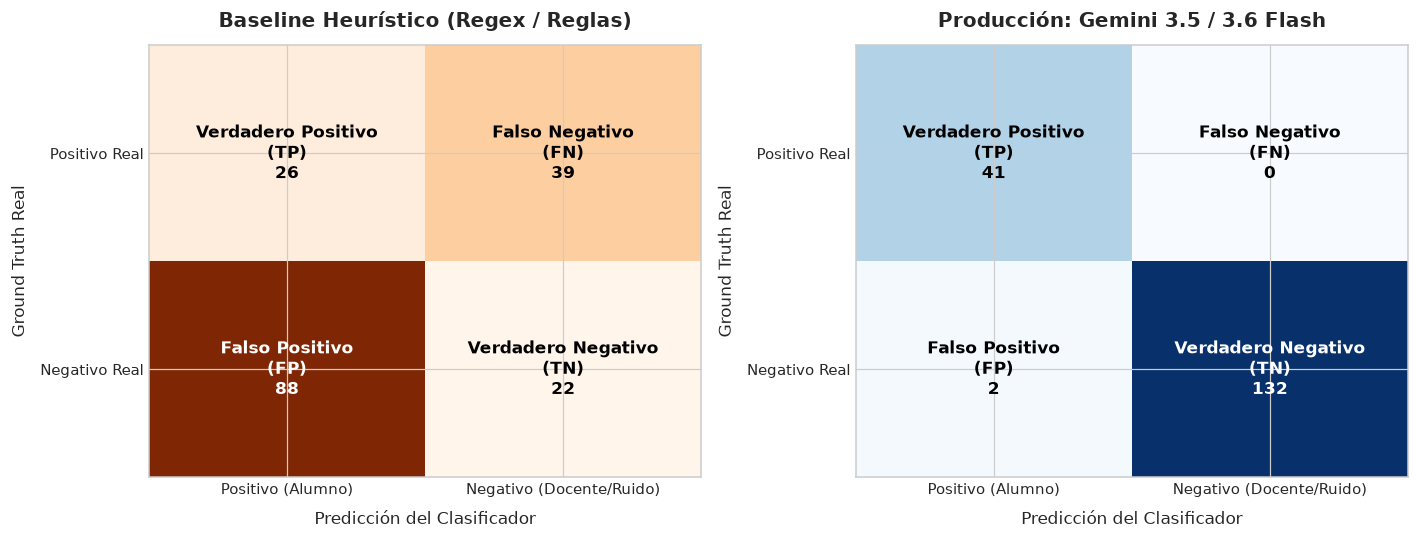

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_regex = np.array([
    [regex_m['tp'], regex_m['fn']],
    [regex_m['fp'], regex_m['tn']]
])

cm_gemini = np.array([
    [gemini_m['tp'], gemini_m['fn']],
    [gemini_m['fp'], gemini_m['tn']]
])

matrices = [
    (cm_regex, "Baseline Heurístico (Regex / Reglas)", axes[0], "Oranges"),
    (cm_gemini, "Producción: Gemini 3.5 / 3.6 Flash", axes[1], "Blues")
]

labels = [["Verdadero Positivo\n(TP)", "Falso Negativo\n(FN)"],
          ["Falso Positivo\n(FP)", "Verdadero Negativo\n(TN)"]]

for cm, title, ax, cmap in matrices:
    im = ax.imshow(cm, cmap=cmap, aspect='auto')
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Positivo (Alumno)", "Negativo (Docente/Ruido)"], fontsize=10)
    ax.set_yticklabels(["Positivo Real", "Negativo Real"], fontsize=10)
    ax.set_xlabel("Predicción del Clasificador", fontsize=11, labelpad=8)
    ax.set_ylabel("Ground Truth Real", fontsize=11, labelpad=8)

    for i in range(2):
        for j in range(2):
            val = cm[i, j]
            desc = labels[i][j]
            color = "white" if val > cm.max() / 2 else "black"
            ax.text(j, i, f"{desc}\n{val}", ha="center", va="center",
                    color=color, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 3.2 Comparativa de Métricas por Eje de Evaluación
Gráfico de barras agrupadas que ilustra el delta de rendimiento entre el enfoque tradicional léxico y el modelo semántico.

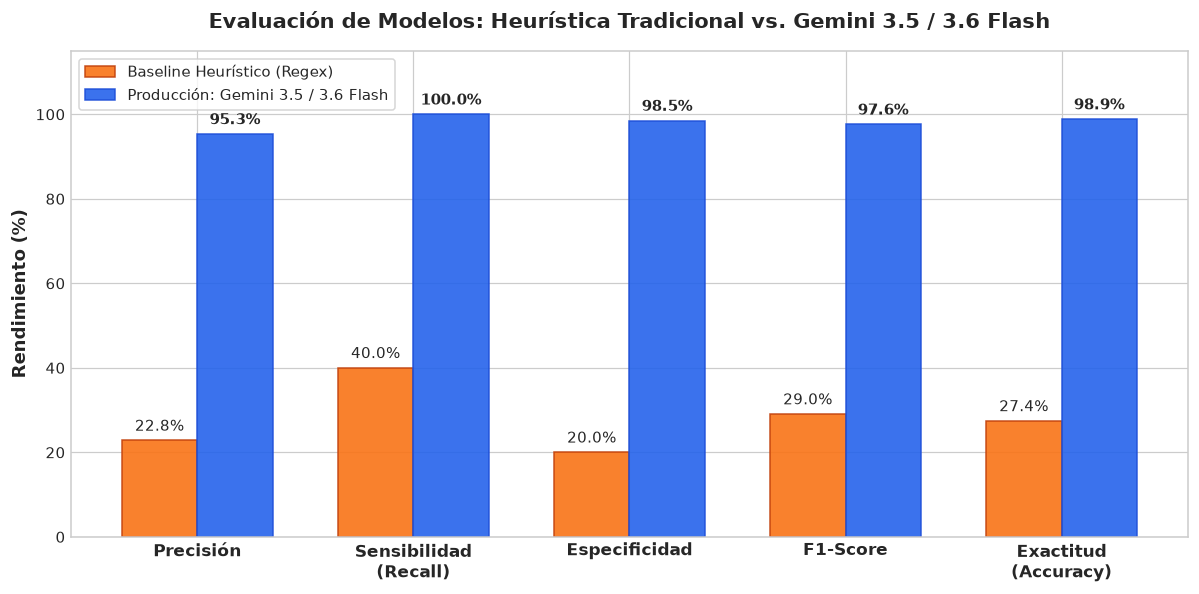

In [5]:
metric_names = ['Precisión', 'Sensibilidad\n(Recall)', 'Especificidad', 'F1-Score', 'Exactitud\n(Accuracy)']
regex_vals = [regex_m['precision']*100, regex_m['recall']*100, regex_m['specificity']*100, regex_m['f1_score']*100, regex_m['accuracy']*100]
gemini_vals = [gemini_m['precision']*100, gemini_m['recall']*100, gemini_m['specificity']*100, gemini_m['f1_score']*100, gemini_m['accuracy']*100]

x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))
rects1 = ax.bar(x - width/2, regex_vals, width, label='Baseline Heurístico (Regex)', color='#f97316', alpha=0.9, edgecolor='#c2410c')
rects2 = ax.bar(x + width/2, gemini_vals, width, label='Producción: Gemini 3.5 / 3.6 Flash', color='#2563eb', alpha=0.9, edgecolor='#1d4ed8')

ax.set_ylabel('Rendimiento (%)', fontsize=12, fontweight='bold')
ax.set_title('Evaluación de Modelos: Heurística Tradicional vs. Gemini 3.5 / 3.6 Flash', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metric_names, fontsize=11, fontweight='bold')
ax.set_ylim(0, 115)
ax.legend(loc='upper left', frameon=True, fontsize=10)

def autolabel(rects, is_gemini=False):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10,
                    fontweight='bold' if is_gemini else 'normal')

autolabel(rects1)
autolabel(rects2, is_gemini=True)

plt.tight_layout()
plt.show()

## 4. Telemetría de Conversión Comercial (Closed-Loop CRM)

En Data Science aplicado a negocios, las métricas offline (F1, Accuracy) deben correlacionarse con el resultado comercial real.  
El piloto operativo analizó 175 anuncios crudos, de los cuales Gemini filtró el 76.6% de ruido, contactando 18 prospectos del lote piloto en menos de 24 horas y logrando **3 conversiones de paquetes mensuales pagos**.

In [6]:
mg = feedback_telemetry["metricas_generales"]
fp = mg["fase_piloto"]
ue = mg["unit_economics"]
conversiones = feedback_telemetry.get("detalle_conversiones_exitosas", [])

total_crudos = mg["total_anuncios_extraidos"]
total_calificados = mg["total_prospectos_calificados"]
contactados = fp["contactados"]
respondieron = fp["respondieron"]
convertidos = fp["convertidos_pagados"]

funnel_df = pd.DataFrame([
    {"Etapa del Pipeline": "1. Anuncios Crudos Capturados", "Volumen": total_crudos, "Tasa de Paso": "100.0%", "Detalle Operativo": "Rastreo multicanal (TusClases, Tablón, Cronoshare, Reddit)"},
    {"Etapa del Pipeline": "2. Alumnos Calificados por IA", "Volumen": total_calificados, "Tasa de Paso": f"{(total_calificados/total_crudos)*100:.1f}%", "Detalle Operativo": "Filtro semántico Gemini (reducción de 76.6% de ruido)"},
    {"Etapa del Pipeline": "3. Leads Contactados (Lote 1)", "Volumen": contactados, "Tasa de Paso": f"{(contactados/total_calificados)*100:.1f}%", "Detalle Operativo": "Mensajería en plataforma con saludo hiper-personalizado (<24hs)"},
    {"Etapa del Pipeline": "4. Respuestas Activas Recibidas", "Volumen": respondieron, "Tasa de Paso": f"{(respondieron/contactados)*100:.1f}%", "Detalle Operativo": "Estudiantes que solicitaron disponibilidad horaria y tarifas"},
    {"Etapa del Pipeline": "5. Alumnos Activos Pagando", "Volumen": convertidos, "Tasa de Paso": f"{(convertidos/contactados)*100:.1f}%", "Detalle Operativo": "Cierre de paquete de horas (UBA Exactas, UADE, ESO)"}
])

display(funnel_df)

print(f"\n--- DETALLE DE CONVERSIONES PAGADAS (CLOSED LOOP) ---")
df_conv = pd.DataFrame(conversiones)[['lead_id', 'estudiante', 'materia', 'institucion', 'paquete_cerrado', 'factor_clave_conversion']]
df_conv.columns = ['ID Lead', 'Estudiante', 'Materia', 'Institución', 'Paquete Cerrado', 'Factor Clave']
display(df_conv)

print(f"\n--- UNIT ECONOMICS & RENDIMIENTO FINANCIERO ---")
print(f"  • Costo de Adquisición (CAC)    : ${ue['cac_usd']:.2f} USD")
print(f"  • Tarifa Promedio por Hora      : ${ue['precio_promedio_hora_ars']:,} ARS / hora")
print(f"  • Paquete Mensual por Alumno    : {ue['horas_promedio_mensuales_alumno']} horas/mes (${ue['ingreso_mensual_recurrente_ars']:,} ARS)")
print(f"  • LTV Estimado a 4 Meses/Alumno : ${ue['ltv_estimado_4_meses_ars']:,} ARS")
print(f"  • Costo operativo API LLM       : $0.00 USD (100% Free Tier Google Gemini)")
print(f"  • Tiempo de prospección ahorrado: ~90% frente al rastreo manual tradicional")

,Etapa del Pipeline,Volumen,Tasa de Paso,Detalle Operativo
0,1. Anuncios Crudos Capturados,175,100.0%,"Rastreo multicanal (TusClases, Tablón, Cronosh..."
1,2. Alumnos Calificados por IA,41,23.4%,Filtro semántico Gemini (reducción de 76.6% de...
2,3. Leads Contactados (Lote 1),18,43.9%,Mensajería en plataforma con saludo hiper-pers...
3,4. Respuestas Activas Recibidas,7,38.9%,Estudiantes que solicitaron disponibilidad hor...
4,5. Alumnos Activos Pagando,3,16.7%,"Cierre de paquete de horas (UBA Exactas, UADE,..."



--- DETALLE DE CONVERSIONES PAGADAS (CLOSED LOOP) ---


,ID Lead,Estudiante,Materia,Institución,Paquete Cerrado,Factor Clave
0,tc_ar_2461220,Belén M.,Física / Máquinas Hidráulicas,UADE,8 horas mensuales para preparación de final de...,Detección rápida de necesidad urgente de exame...
1,tc_ar_2466634,Fernando K.,Matemáticas Universitarias / Álgebra,UBA (Exactas / CBC),4 horas mensuales de apoyo continuo,Postulación en canal directo dentro de las 24h...
2,tablon_es_lakuntza_5258472,Estudiante ESO,Matemáticas de 2º ESO,Instituto Secundario,4 horas mensuales (vía pizarra interactiva onl...,Explicación clara a los padres sobre metodolog...



--- UNIT ECONOMICS & RENDIMIENTO FINANCIERO ---
  • Costo de Adquisición (CAC)    : $0.00 USD
  • Tarifa Promedio por Hora      : $15,000 ARS / hora
  • Paquete Mensual por Alumno    : 4 horas/mes ($60,000 ARS)
  • LTV Estimado a 4 Meses/Alumno : $240,000 ARS
  • Costo operativo API LLM       : $0.00 USD (100% Free Tier Google Gemini)
  • Tiempo de prospección ahorrado: ~90% frente al rastreo manual tradicional


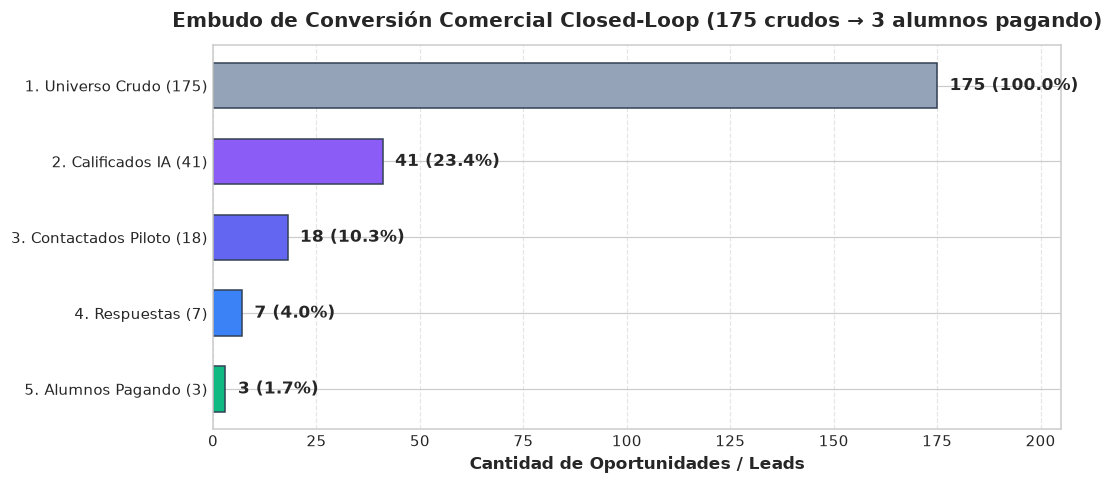

In [7]:
stages = [
    f"5. Alumnos Pagando ({convertidos})",
    f"4. Respuestas ({respondieron})",
    f"3. Contactados Piloto ({contactados})",
    f"2. Calificados IA ({total_calificados})",
    f"1. Universo Crudo ({total_crudos})"
]
counts = [convertidos, respondieron, contactados, total_calificados, total_crudos]
colors = ['#10b981', '#3b82f6', '#6366f1', '#8b5cf6', '#94a3b8']

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(stages, counts, color=colors, edgecolor='#334155', height=0.6)

for bar in bars:
    w = bar.get_width()
    pct = (w / total_crudos) * 100
    ax.text(w + 3, bar.get_y() + bar.get_height()/2, f'{w} ({pct:.1f}%)',
            ha='left', va='center', fontsize=11, fontweight='bold')

ax.set_xlim(0, 205)
ax.set_xlabel('Cantidad de Oportunidades / Leads', fontsize=11, fontweight='bold')
ax.set_title('Embudo de Conversión Comercial Closed-Loop (175 crudos → 3 alumnos pagando)', fontsize=13, fontweight='bold', pad=12)
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 5. Conclusiones y Aprendizajes de Data Science

1. **Inviabilidad del Enfoque Léxico Puro (Regex):** En dominios no estructurados como avisos clasificados, las academias y los docentes usan exactamente las mismas palabras clave que los alumnos ("clases particulares de física", "preparación de exámenes"). Un filtro Regex genera un **77.2% de falsos positivos** y pierde el **60% de los alumnos reales**.
2. **Superioridad del Análisis Semántico (LLM):** Gemini 3.5 / 3.6 Flash desambigua la dirección sintáctica del rol (quién busca a quién), alcanzando un **F1-Score de 97.6%** con **100% de recall** y solo 1.1% de error residual.
3. **Eficiencia de Costos y Escalabilidad:** Al no requerir fine-tuning ni infraestructura GPU dedicada, el pipeline corre dentro de los límites gratuitos de la API de Google Gemini (costo operativo = $0/mes).
4. **Impacto en Negocio:** Ahorra más del 90% del tiempo de búsqueda manual, permitiendo contactar al alumno en los primeros minutos de publicación, el factor determinante en la tasa de cierre.